# Measuring promotion lift: naive comparisons vs difference-in-differences (with a known ground truth)

**Question.** A retailer runs a promotion in some stores starting in week 30. How much extra volume did it *cause*, and how badly do simple comparisons mislead?

**Why synthetic data.** With real retail data the true effect is unknown, so you cannot tell whether an estimator is right. Here the data is **simulated with a known true lift**, so we can check which methods recover it and watch them fail when their assumptions are broken. This notebook demonstrates *method behavior*. It does not estimate any real-world effect.

**Approach**
1. Simulate a store × week panel (store size, trend, seasonality, a holiday spike, noise) with a promotion in a subset of stores.
2. Compare three estimates against the truth: a naive promo-vs-non-promo comparison, a naive before/after comparison, and **difference-in-differences** (two-way fixed effects, cluster-robust SEs).
3. Check the key assumption (**parallel trends**) with an **event study** and a **placebo test**.
4. Break the assumption on purpose (treated stores on a steeper growth path) and see what happens, and what partly fixes it.

| Section | Content |
|---|---|
| 0 | Setup |
| 1 | Simulated panel |
| 2 | Scenario A: parallel trends hold |
| 3 | Event study and placebo test |
| 4 | Scenario B: parallel trends violated |
| 5 | Summary and limitations |

## 0. Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": .3})

SEED = 2026
N_STORES, N_WEEKS, T0 = 80, 52, 30      # promotion starts in week 30
TREATED_SHARE = 0.40
TRUE_LIFT = 0.15                         # true effect on LOG sales, i.e. about +16.2% volume
print(f"True effect: {TRUE_LIFT:.3f} log points = {np.expm1(TRUE_LIFT):.1%} volume lift")

True effect: 0.150 log points = 16.2% volume lift


## 1. Simulated panel
For store $i$ in week $t$:

$$\log y_{it} = a_i + g_i\,t + c\,t + s_t + \tau\,D_{it} + \varepsilon_{it}$$

- $a_i$: store size (log level); larger stores are **more likely to be chosen** for the promotion (selection on level, which DiD handles).
- $g_i$: store-specific trend; $c\,t$: common trend; $s_t$: seasonality plus a **holiday spike in weeks 44-48**, which falls after the promotion starts and fools naive before/after comparisons.
- $D_{it}=1$ for treated stores from week `T0` onward, with true effect $\tau$ = `TRUE_LIFT`.
- $\varepsilon_{it}$: noise.

In scenario B, treated stores also have a **steeper trend** (`diff_trend`), which violates parallel trends.

(4160, 6) | treated stores: 32 of 80


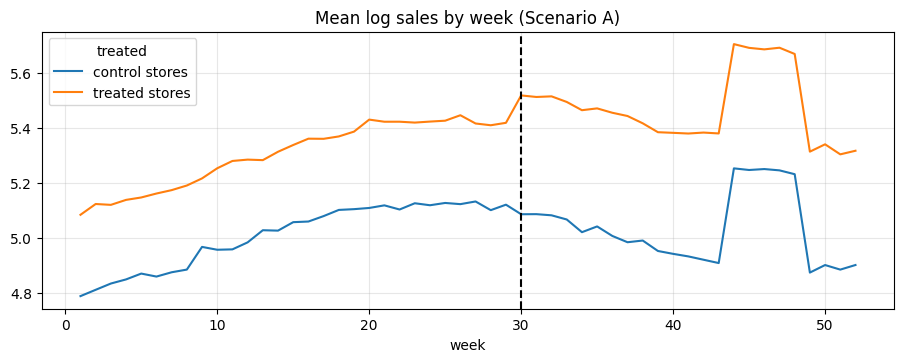

In [2]:
def simulate_panel(diff_trend=0.0, seed=SEED, n_stores=N_STORES, n_weeks=N_WEEKS, t0=T0,
                   share=TREATED_SHARE, tau=TRUE_LIFT, noise=0.08):
    g = np.random.default_rng(seed)
    store_level = g.normal(5.0, 0.4, n_stores)                                # log baseline volume
    p_treat = 1 / (1 + np.exp(-(store_level - 5.0) * 3))                      # bigger stores more likely treated
    treated = np.zeros(n_stores, int)
    treated[g.choice(n_stores, int(share * n_stores), replace=False, p=p_treat / p_treat.sum())] = 1
    own_trend = g.normal(0.0, 0.001, n_stores) + diff_trend * treated

    weeks = np.arange(1, n_weeks + 1)
    season = 0.15 * np.sin(2 * np.pi * (weeks - 10) / 52) + 0.35 * ((weeks >= 44) & (weeks <= 48))
    common = 0.002 * weeks

    rows = []
    for i in range(n_stores):
        d = treated[i] * (weeks >= t0)
        logy = store_level[i] + own_trend[i] * weeks + common + season + tau * d + g.normal(0, noise, n_weeks)
        rows.append(pd.DataFrame({"store": i, "week": weeks, "treated": treated[i], "post": (weeks >= t0).astype(int),
                                  "treat_post": d, "logy": logy}))
    return pd.concat(rows, ignore_index=True)

dfA = simulate_panel(diff_trend=0.0)
print(dfA.shape, "| treated stores:", dfA.groupby("store").treated.first().sum(), "of", N_STORES)
m = dfA.groupby(["week", "treated"]).logy.mean().unstack()
ax = m.rename(columns={0: "control stores", 1: "treated stores"}).plot(title="Mean log sales by week (Scenario A)")
ax.axvline(T0, color="k", ls="--"); plt.show()

## 2. Scenario A: parallel trends hold
Four estimates of the same quantity, compared with the truth:

1. **Naive: promo vs non-promo observations.** Mean of treated-store post-period weeks minus mean of everything else. It mixes store size, season and the promotion.
2. **Naive: before vs after in treated stores.** Absorbs the seasonal spike and trend.
3. **DiD (2×2 means).** (treated after − treated before) − (control after − control before).
4. **DiD regression (two-way fixed effects).** `logy ~ treat_post + store FE + week FE`, with standard errors clustered by store.

In [3]:
def estimates(df, label):
    promo = df.treat_post == 1
    naive_promo = df.loc[promo, "logy"].mean() - df.loc[~promo, "logy"].mean()
    tr = df[df.treated == 1]
    naive_prepost = tr.loc[tr.post == 1, "logy"].mean() - tr.loc[tr.post == 0, "logy"].mean()
    cell = df.groupby(["treated", "post"]).logy.mean()
    did_means = (cell[1, 1] - cell[1, 0]) - (cell[0, 1] - cell[0, 0])
    fit = smf.ols("logy ~ treat_post + C(store) + C(week)", df).fit(cov_type="cluster", cov_kwds={"groups": df["store"]})
    b, se = fit.params["treat_post"], fit.bse["treat_post"]
    out = pd.DataFrame({
        "estimate (log pts)": [naive_promo, naive_prepost, did_means, b],
        "implied % lift": [np.expm1(v) for v in (naive_promo, naive_prepost, did_means, b)],
        "error vs truth (log pts)": [v - TRUE_LIFT for v in (naive_promo, naive_prepost, did_means, b)]},
        index=["Naive: promo vs non-promo obs.", "Naive: before vs after (treated)", "DiD (2x2 means)", "DiD regression (TWFE)"])
    print(f"--- {label} ---  true effect = {TRUE_LIFT:.3f} log pts ({np.expm1(TRUE_LIFT):.1%})")
    print(out.round(3))
    print(f"DiD regression 95% CI: [{b - 1.96*se:.3f}, {b + 1.96*se:.3f}]  (covers truth: {b - 1.96*se <= TRUE_LIFT <= b + 1.96*se})\n")
    return out, (b, se)

outA, (bA, seA) = estimates(dfA, "Scenario A (parallel trends hold)")

--- Scenario A (parallel trends hold) ---  true effect = 0.150 log pts (16.2%)
                                  estimate (log pts)  implied % lift  \
Naive: promo vs non-promo obs.                 0.377           0.458   
Naive: before vs after (treated)               0.171           0.186   
DiD (2x2 means)                                0.145           0.156   
DiD regression (TWFE)                          0.145           0.156   

                                  error vs truth (log pts)  
Naive: promo vs non-promo obs.                       0.227  
Naive: before vs after (treated)                     0.021  
DiD (2x2 means)                                     -0.005  
DiD regression (TWFE)                               -0.005  
DiD regression 95% CI: [0.127, 0.163]  (covers truth: True)



**Reading the results.** The naive promo-vs-non-promo number is inflated because treated stores are larger and the post period contains the holiday spike. The before/after number also absorbs the spike. DiD removes anything that is common to treated and control stores (seasonality, the spike, common trend) and any constant store differences (size), leaving the promotion effect.

## 3. Checking the assumption: event study and placebo test
DiD is only credible if treated and control stores would have moved **in parallel** without the promotion. We cannot observe that counterfactual, but we can check the **pre-period**:

- **Event study.** Estimate a separate treated-vs-control gap for each week relative to the promotion start (reference: week −1). Before the promotion these coefficients should hover around zero, with no trend. After it they should jump to about the true effect.
- **Placebo test.** Pretend the promotion started earlier, in the pre-period only. The estimated "effect" should be statistically indistinguishable from zero. Note that a 5%-level test rejects by chance about 5% of the time even when the assumption holds, so a single run is only an anecdote. The Monte Carlo in Section 4 reports rates.

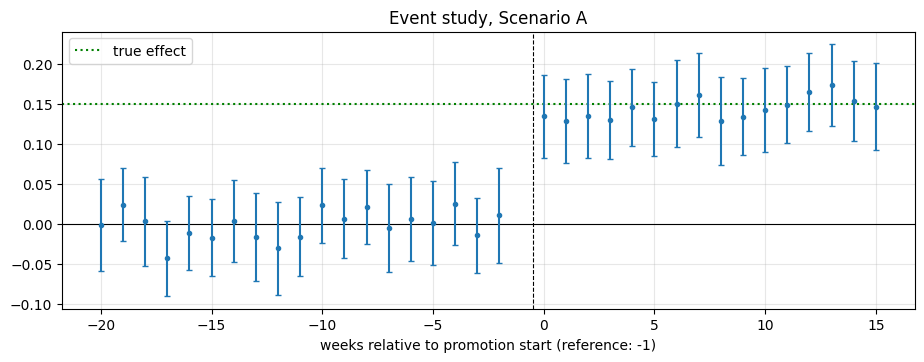

Pre-period coefficients: mean = -0.001, linear slope = +0.0009 per week (share of 95% CIs containing 0: 100%)
Placebo (fake start week 20, pre-period only): effect = +0.017, p = 0.049


In [4]:
def event_study(df, lo=-20, hi=15, t0=T0, ref=-1):
    d = df.copy(); d["rel"] = d["week"] - t0
    d = d[(d.rel >= lo) & (d.rel <= hi)]
    ks = [k for k in range(lo, hi + 1) if k != ref]
    for k in ks:
        d[f"ev_{'m' if k < 0 else 'p'}{abs(k)}"] = ((d.treated == 1) & (d.rel == k)).astype(int)
    cols = [f"ev_{'m' if k < 0 else 'p'}{abs(k)}" for k in ks]
    fit = smf.ols("logy ~ " + " + ".join(cols) + " + C(store) + C(week)", d).fit(cov_type="cluster", cov_kwds={"groups": d["store"]})
    est = fit.params[cols].values; ci = fit.conf_int().loc[cols].values
    return pd.DataFrame({"rel_week": ks, "coef": est, "lo": ci[:, 0], "hi": ci[:, 1]})

def plot_event(es, ax, title):
    ax.axhline(0, color="k", lw=.8); ax.axvline(-0.5, color="k", ls="--", lw=.8)
    ax.axhline(TRUE_LIFT, color="g", ls=":", label="true effect")
    ax.errorbar(es.rel_week, es.coef, yerr=[es.coef - es.lo, es.hi - es.coef], fmt="o", ms=3, capsize=2)
    ax.set_title(title); ax.set_xlabel("weeks relative to promotion start (reference: -1)"); ax.legend()

def placebo(df, fake_t0=20, t0=T0):
    d = df[df.week < t0].copy(); d["fake"] = ((d.treated == 1) & (d.week >= fake_t0)).astype(int)
    fit = smf.ols("logy ~ fake + C(store) + C(week)", d).fit(cov_type="cluster", cov_kwds={"groups": d["store"]})
    return fit.params["fake"], fit.pvalues["fake"]

esA = event_study(dfA)
pre = esA[esA.rel_week < 0]
slope = np.polyfit(pre.rel_week, pre.coef, 1)[0]
pbA, ppA = placebo(dfA)
fig, ax = plt.subplots(figsize=(11, 3.6)); plot_event(esA, ax, "Event study, Scenario A"); plt.show()
print(f"Pre-period coefficients: mean = {pre.coef.mean():+.3f}, linear slope = {slope:+.4f} per week "
      f"(share of 95% CIs containing 0: {((pre.lo <= 0) & (pre.hi >= 0)).mean():.0%})")
print(f"Placebo (fake start week 20, pre-period only): effect = {pbA:+.3f}, p = {ppA:.3f}")

## 4. Scenario B: parallel trends violated
Now the treated stores are on a **steeper growth path** even without the promotion (e.g. the retailer picked fast-growing stores). The same estimators run on the new data.

--- Scenario B (treated stores grow 0.004/week faster) ---  true effect = 0.150 log pts (16.2%)
                                  estimate (log pts)  implied % lift  \
Naive: promo vs non-promo obs.                 0.519           0.680   
Naive: before vs after (treated)               0.280           0.323   
DiD (2x2 means)                                0.257           0.293   
DiD regression (TWFE)                          0.257           0.293   

                                  error vs truth (log pts)  
Naive: promo vs non-promo obs.                       0.369  
Naive: before vs after (treated)                     0.130  
DiD (2x2 means)                                      0.107  
DiD regression (TWFE)                                0.107  
DiD regression 95% CI: [0.240, 0.274]  (covers truth: False)



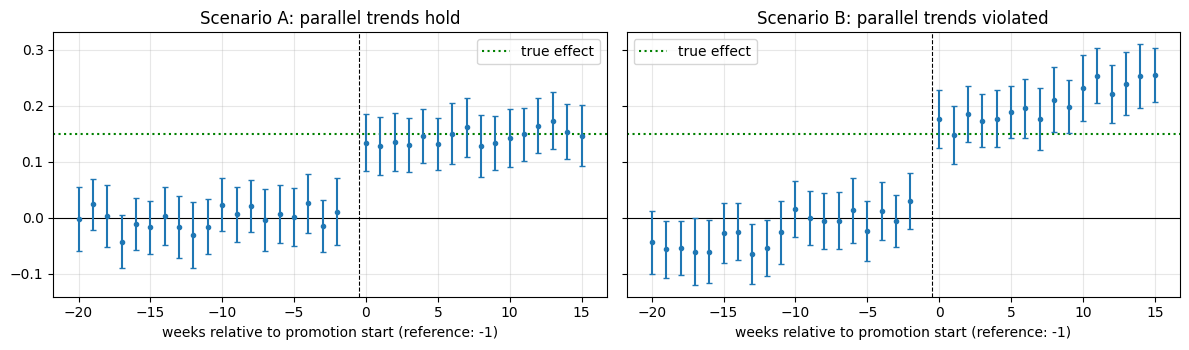

Scenario B pre-period slope = +0.0043 per week; placebo effect = +0.064 (p = 0.000)


In [5]:
DIFF_TREND = 0.004                       # extra weekly log growth in treated stores
dfB = simulate_panel(diff_trend=DIFF_TREND, seed=SEED + 1)
outB, (bB, seB) = estimates(dfB, f"Scenario B (treated stores grow {DIFF_TREND:.3f}/week faster)")

esB = event_study(dfB); preB = esB[esB.rel_week < 0]
slopeB = np.polyfit(preB.rel_week, preB.coef, 1)[0]
pbB, ppB = placebo(dfB)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
plot_event(esA, ax[0], "Scenario A: parallel trends hold"); plot_event(esB, ax[1], "Scenario B: parallel trends violated")
plt.tight_layout(); plt.show()
print(f"Scenario B pre-period slope = {slopeB:+.4f} per week; placebo effect = {pbB:+.3f} (p = {ppB:.3f})")

**Reading the results.** Compare the two event-study panels and the printed pre-period slopes: when parallel trends fail, the pre-period coefficients trend instead of scattering around zero, and the placebo test finds a spurious "effect" before any promotion happened. The plain DiD estimate then absorbs the extra growth into the promotion effect. One partial fix is to give each store its own linear trend (below). It only helps if the trend really is linear and is identified by the pre-period.

In [6]:
fitB_trend = smf.ols("logy ~ treat_post + C(store) + C(week) + C(store):week", dfB).fit(cov_type="cluster", cov_kwds={"groups": dfB["store"]})
bT, seT = fitB_trend.params["treat_post"], fitB_trend.bse["treat_post"]
print(f"Scenario B, plain DiD (TWFE)             : {bB:+.3f} (error {bB - TRUE_LIFT:+.3f})")
print(f"Scenario B, DiD + store-specific trends  : {bT:+.3f} (error {bT - TRUE_LIFT:+.3f}), 95% CI [{bT - 1.96*seT:.3f}, {bT + 1.96*seT:.3f}]")

Scenario B, plain DiD (TWFE)             : +0.257 (error +0.107)
Scenario B, DiD + store-specific trends  : +0.152 (error +0.002), 95% CI [0.133, 0.171]


### Monte Carlo: how often do the diagnostics and the CI behave?
A single simulated dataset can mislead (a placebo test rejects by chance about 5% of the time). The cell below repeats each scenario 100 times with fresh data and reports the mean DiD estimate, the coverage of its 95% confidence interval, and how often the placebo test rejects at 5%.

In [7]:
def monte_carlo(diff_trend, n_rep=100, base_seed=1000):
    rows = []
    for r in range(n_rep):
        d = simulate_panel(diff_trend=diff_trend, seed=base_seed + r)
        fit = smf.ols("logy ~ treat_post + C(store) + C(week)", d).fit(cov_type="cluster", cov_kwds={"groups": d["store"]})
        b, se = fit.params["treat_post"], fit.bse["treat_post"]
        rows.append((b, b - 1.96 * se <= TRUE_LIFT <= b + 1.96 * se, placebo(d)[1] < 0.05))
    return pd.DataFrame(rows, columns=["est", "covers", "placebo_rejects"])

mc = {}
for name, dt in [("A: parallel trends hold", 0.0), ("B: parallel trends violated", DIFF_TREND)]:
    r_ = monte_carlo(dt)
    mc[name] = {"mean DiD estimate": r_.est.mean(), "bias vs truth": r_.est.mean() - TRUE_LIFT,
                "95% CI coverage": r_.covers.mean(), "placebo rejects (5% test)": r_.placebo_rejects.mean()}
mc_tab = pd.DataFrame(mc).T
print(f"True effect = {TRUE_LIFT:.3f} log pts;  100 simulated datasets per scenario"); print(mc_tab.round(3))

True effect = 0.150 log pts;  100 simulated datasets per scenario
                             mean DiD estimate  bias vs truth  \
A: parallel trends hold                  0.151          0.001   
B: parallel trends violated              0.255          0.105   

                             95% CI coverage  placebo rejects (5% test)  
A: parallel trends hold                 0.94                       0.06  
B: parallel trends violated             0.00                       1.00  


## 5. Summary and limitations

In [8]:
rowsA = outA["estimate (log pts)"]; rowsB = outB["estimate (log pts)"]
print(f"True effect: {TRUE_LIFT:.3f} log pts ({np.expm1(TRUE_LIFT):.1%} volume lift)\n")
print("Scenario A (parallel trends hold)")
print(f"  naive promo vs non-promo : {rowsA.iloc[0]:+.3f}   naive before/after : {rowsA.iloc[1]:+.3f}   DiD (TWFE) : {rowsA.iloc[3]:+.3f}")
print(f"  event-study pre-trend slope {slope:+.4f}/wk; placebo p = {ppA:.3f}")
print("Scenario B (parallel trends violated)")
print(f"  naive promo vs non-promo : {rowsB.iloc[0]:+.3f}   naive before/after : {rowsB.iloc[1]:+.3f}   DiD (TWFE) : {rowsB.iloc[3]:+.3f}   DiD + store trends : {bT:+.3f}")
print(f"  event-study pre-trend slope {slopeB:+.4f}/wk; placebo p = {ppB:.3f}")
print("\nMonte Carlo (100 datasets per scenario):"); print(mc_tab.round(3))

True effect: 0.150 log pts (16.2% volume lift)

Scenario A (parallel trends hold)
  naive promo vs non-promo : +0.377   naive before/after : +0.171   DiD (TWFE) : +0.145
  event-study pre-trend slope +0.0009/wk; placebo p = 0.049
Scenario B (parallel trends violated)
  naive promo vs non-promo : +0.519   naive before/after : +0.280   DiD (TWFE) : +0.257   DiD + store trends : +0.152
  event-study pre-trend slope +0.0043/wk; placebo p = 0.000

Monte Carlo (100 datasets per scenario):
                             mean DiD estimate  bias vs truth  \
A: parallel trends hold                  0.151          0.001   
B: parallel trends violated              0.255          0.105   

                             95% CI coverage  placebo rejects (5% test)  
A: parallel trends hold                 0.94                       0.06  
B: parallel trends violated             0.00                       1.00  


### What this demonstrates
- Naive comparisons confuse the promotion with store size, seasonality and trend. DiD, with fixed effects and clustered SEs, recovers the truth when its assumptions hold.
- The assumption can be **checked, not proven**: the event-study pre-trend and the placebo test are the diagnostics, and they fire when parallel trends fail.

### Limitations
- **Synthetic data.** The effect is known by construction, and the real world is messier. This shows how the methods behave, not how large any real promotion effect is.
- **Constant, immediate effect.** Real promotions ramp up, decay, shift demand across time (pull-forward) and across products (cannibalization).
- **No spillovers (SUTVA).** Customers shifting between nearby stores would contaminate the control group.
- **Stockouts censor demand.** Observed sales understate true demand when inventory runs out.
- **Single start date.** With staggered rollouts and heterogeneous effects, two-way fixed effects can be biased; modern estimators (e.g. Callaway-Sant'Anna) are designed for that case.
- **Few treated clusters** would need wild-bootstrap or other small-cluster inference.

### Next steps
- Apply the same event-study / placebo workflow to real retail data (e.g. a public retail or promotion dataset) and report assumptions explicitly.
- Compare with **synthetic control** or **CausalImpact** for a single treated unit.
- Try **double ML** (e.g. EconML) when treatment is not a clean on/off switch.
- Feed the lift estimate into a forecasting pipeline as a promotion feature or what-if scenario.